In [1]:
# Update yfinance to the newest version, because Colab's default copy is often outdated
!pip install -U yfinance

  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.66
    Uninstalling yfinance-0.2.66:
      Successfully uninstalled yfinance-0.2.66


In [2]:
#load the libraries, create the data folders and set the study period and benchmark
import os
import time
import platform
import datetime as dt
import pandas as pd
import numpy as np
import yfinance as yf

#Make folders to store our data (nothing happens if they already exist)
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

#The study period from the coursework brief (the end date is NOT included)
START = "2021-01-01"
END = "2025-01-01"
BENCHMARK = "^GSPC"   # the S&P 500 index

#Print the package versions - copy these into requirements.txt later
print("Python  :", platform.python_version())
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("yfinance:", yf.__version__)

Python  : 3.13.18
pandas  : 2.2.3
numpy   : 2.4.6
yfinance: 1.8.0


**Task 1 - Data Preparation and Feature Engineering**

In [3]:
#Task 1.1 - Ticker selection
#Get the current S&P 500 company list from Wikipedia and save it with its retrieval date
URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Note the exact time we pulled the list (the brief asks for the retrieval date)
retrieved_at = dt.datetime.now(dt.timezone.utc)

# Read the tables on the page. The header makes Wikipedia think we're a browser
tables = pd.read_html(URL, storage_options={"User-Agent": "Mozilla/5.0"})
constituents = tables[0].copy()   # the first table is the current company list

# Yahoo writes tickers like BRK-B, but Wikipedia writes BRK.B, so convert them
constituents["yahoo_ticker"] = constituents["Symbol"].str.replace(".", "-", regex=False)

# Keep a record of where and when this list came from
constituents["source_url"] = URL
constituents["retrieved_utc"] = retrieved_at.strftime("%Y-%m-%d %H:%M")

# Save it straight away, because Wikipedia changes over time
constituents.to_csv("data/raw/sp500_constituents.csv", index=False)

# Quick checks
print("Companies found     :", len(constituents))
print("Duplicate tickers   :", constituents["yahoo_ticker"].duplicated().sum())
print("Missing sectors     :", constituents["GICS Sector"].isna().sum())
print("Retrieved on        :", retrieved_at.strftime("%Y-%m-%d"))
constituents[["Symbol", "yahoo_ticker", "Security", "GICS Sector"]].head()

Companies found     : 503
Duplicate tickers   : 0
Missing sectors     : 0
Retrieved on        : 2026-11-23


,Symbol,yahoo_ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


In [4]:
#Task 1.1 - Data acquistion: Daily prices, adjusted price and volume
#Download daily prices and volume for every ticker, in batches of 50 to avoid Yahoo blocking us
#yfinance only prints an error when a single ticker fails, so "Failed batches: 0" does not mean
#Every ticker worked. The real check is the list of tickers with no data in Step 7.
tickers = constituents["yahoo_ticker"].tolist()

#Downloading 500 shares at once often gets blocked, so go 50 at a time
batch_size = 50
batches = [tickers[i:i + batch_size] for i in range(0, len(tickers), batch_size)]

downloaded_parts = []
failed_batches = []

for number, batch in enumerate(batches, start=1):
    print(f"Downloading batch {number} of {len(batches)}...")
    try:
        # auto_adjust=False keeps BOTH Close and Adj Close (we need both later)
        part = yf.download(batch, start=START, end=END,
                           auto_adjust=False, progress=False)
        downloaded_parts.append(part)
    except Exception as error:
        print("  Batch failed:", error)
        failed_batches.append(batch)
    time.sleep(2)   # short pause so Yahoo doesn't block us

# Join all the batches together into one big table
raw = pd.concat(downloaded_parts, axis=1)

print("Done. Table size:", raw.shape)
print("Failed batches  :", len(failed_batches))

ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


ERROR:yfinance:$SNDK: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Done. Table size: (1005, 3018)
Failed batches  : 0


In [5]:
#Task 1.1 - Data acquisition: S&P 500 benchmark
#Download the S&P 500 index (^GSPC) for the same period, to use as the market benchmark later
bench = yf.download(BENCHMARK, start=START, end=END,
                    auto_adjust=False, progress=False)

# Newer yfinance versions return two-level column names, so flatten them
if isinstance(bench.columns, pd.MultiIndex):
    bench.columns = bench.columns.get_level_values(0)

print("First date:", bench.index.min().date())
print("Last date :", bench.index.max().date())
print("Rows      :", len(bench))

First date: 2021-01-04
Last date : 2024-12-31
Rows      : 1005


In [6]:
#Task 1.1 - Preserved dataset: save row data snapshots
#Save each price type in its own file, so they are easy to reload later
for field in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]:
    filename = "data/raw/prices_" + field.replace(" ", "_").lower() + ".csv"
    raw[field].to_csv(filename)

# Save the benchmark too
bench.to_csv("data/raw/gspc_benchmark.csv")

print(os.listdir("data/raw"))

['sp500_constituents.csv', 'prices_low.csv', 'prices_volume.csv', 'gspc_benchmark.csv', 'prices_high.csv', 'prices_adj_close.csv', 'prices_open.csv', 'prices_close.csv']


In [7]:
#Task 1.1 - Acquisition check: coverage, dates, tickers with no data
#Check what we actually got (dates, trading days, tickers with and without data) and start the log
adj = raw["Adj Close"]

# Which tickers actually returned some data?
has_data = adj.columns[adj.notna().any()].tolist()
no_data = sorted(set(tickers) - set(has_data))

print("First date        :", adj.index.min().date())
print("Last date         :", adj.index.max().date())
print("Trading days      :", len(adj))
print("Tickers requested :", len(tickers))
print("Tickers with data :", len(has_data))
print("Tickers, no data  :", no_data)

# Start the acquisition log: one row per ticker. We add more to it in Task 1.2
log = pd.DataFrame({"ticker": tickers})
log["data_returned"] = log["ticker"].isin(has_data)
log["first_date"] = log["ticker"].map(adj.apply(lambda s: s.first_valid_index()))
log["last_date"] = log["ticker"].map(adj.apply(lambda s: s.last_valid_index()))
log["n_rows"] = log["ticker"].map(adj.notna().sum())
log.to_csv("data/processed/acquisition_log.csv", index=False)
log.head()

First date        : 2021-01-04
Last date         : 2024-12-31
Trading days      : 1005
Tickers requested : 503
Tickers with data : 498
Tickers, no data  : ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


,ticker,data_returned,first_date,last_date,n_rows
0,MMM,True,2021-01-04,2024-12-31,1005
1,AOS,True,2021-01-04,2024-12-31,1005
2,ABT,True,2021-01-04,2024-12-31,1005
3,ABBV,True,2021-01-04,2024-12-31,1005
4,ACN,True,2021-01-04,2024-12-31,1005


In [8]:
#Execution log
#Note why each ticker has no data (for the exclusion log)
log["reason"] = ""
log.loc[~log["data_returned"], "reason"] = "No price data returned for 2021-2024"

# Also flag shares with fewer rows than the benchmark (short history)
bench_rows = len(adj)
short = log["data_returned"] & (log["n_rows"] < bench_rows)
log.loc[short, "reason"] = "Short history: fewer than " + str(bench_rows) + " trading days"

print("No data      :", (~log["data_returned"]).sum())
print("Short history:", short.sum())
log.to_csv("data/processed/acquisition_log.csv", index=False)
log[log["reason"] != ""]

No data      : 5
Short history: 10


,ticker,data_returned,first_date,last_date,n_rows,reason
40,APP,True,2021-04-15,2024-12-31,935,Short history: fewer than 1005 trading days
116,COIN,True,2021-04-14,2024-12-31,936,Short history: fewer than 1005 trading days
123,CEG,True,2022-01-19,2024-12-31,742,Short history: fewer than 1005 trading days
181,EXE,True,2021-02-10,2024-12-31,979,Short history: fewer than 1005 trading days
192,FDXF,False,NaT,NaT,0,No price data returned for 2021-2024
210,GEHC,True,2022-12-15,2024-12-31,513,Short history: fewer than 1005 trading days
211,GEV,True,2024-03-27,2024-12-31,193,Short history: fewer than 1005 trading days
233,HONA,False,NaT,NaT,0,No price data returned for 2021-2024
379,Q,False,NaT,NaT,0,No price data returned for 2021-2024
385,RDDT,True,2024-03-21,2024-12-31,197,Short history: fewer than 1005 trading days


**Task 1.2 - Data Validation**

In [9]:
#Task 1.2 - validation: duplicate dates, ordering, benchmark alignment
#Check the dates are clean (no repeats, in order, same days for shares and benchmark)
close = raw["Close"]      # raw closing prices, needed later for the Monetary measure
vol = raw["Volume"]       # number of shares traded each day

print("Duplicate dates in shares     :", adj.index.duplicated().sum())
print("Duplicate dates in benchmark  :", bench.index.duplicated().sum())
print("Dates in order                :", adj.index.is_monotonic_increasing)
print("Share dates = benchmark dates :", adj.index.equals(bench.index))

Duplicate dates in shares     : 0
Duplicate dates in benchmark  : 0
Dates in order                : True
Share dates = benchmark dates : True


In [10]:
#Task 1.2 - validation: missing values, nonpositive prices, volume errors
#For shares with a full history, count missing values, bad prices and volume problems
full_set = log.loc[log["data_returned"] & (log["n_rows"] == len(adj)), "ticker"].tolist()
print("Shares with a full history:", len(full_set))

checks = pd.DataFrame(index=full_set)
checks["missing_close"] = close[full_set].isna().sum()
checks["missing_adj_close"] = adj[full_set].isna().sum()
checks["missing_volume"] = vol[full_set].isna().sum()
checks["nonpositive_price"] = (close[full_set] <= 0).sum() + (adj[full_set] <= 0).sum()
checks["negative_volume"] = (vol[full_set] < 0).sum()
checks["zero_volume_days"] = (vol[full_set] == 0).sum()

#Totals across all shares: ideally zero, or a short list we can explain
print(checks.sum())

#Show any share with at least one problem
checks[(checks > 0).any(axis=1)]

Shares with a full history: 488
missing_close          0
missing_adj_close      0
missing_volume         0
nonpositive_price      0
negative_volume        0
zero_volume_days     451
dtype: int64


,missing_close,missing_adj_close,missing_volume,nonpositive_price,negative_volume,zero_volume_days
FERG,0,0,0,0,0,27
SW,0,0,0,0,0,424


In [11]:
#Task 1.2 - validation: corporate actions (Adj Close vs Close, large moves)
#look for signs of unadjusted splits or odd jumps (my own screening thresholds: 10% and 40%)
ratio = adj[full_set] / close[full_set]        #drifts slowly if only dividends are involved
ratio_jump = ratio.pct_change(fill_method=None).abs().max()

daily_ret = adj[full_set].pct_change(fill_method=None)
#one-day moves above 40%
big_moves = (daily_ret.abs() > 0.40).sum()

print("Shares where Adj/Close ratio jumps over 10% :", (ratio_jump > 0.10).sum())
print("Shares with a one-day move above 40%        :", (big_moves > 0).sum())

#List them so each one can be inspected
print(ratio_jump[ratio_jump > 0.10])
print(big_moves[big_moves > 0])

Shares where Adj/Close ratio jumps over 10% : 0
Shares with a one-day move above 40%        : 4
Series([], dtype: float64)
Ticker
BE      1
CVNA    5
DXCM    1
GL      1
dtype: int64


In [12]:
#Task 1.2  - inclusion & exclusion log, final share set
#Decide which shares are included, give every excluded one a reason, and save the log
final_log = log.copy()
final_log["included"] = True

#Rule 1: no price data returned at all
final_log.loc[~final_log["data_returned"], "included"] = False

#Rule 2: history shorter than the full study period (unequal histories)
final_log.loc[final_log["reason"].str.startswith("Short history"), "included"] = False

#Rule 3: hard data errors in the full-history shares
error_cols = ["missing_close", "missing_adj_close", "missing_volume",
              "nonpositive_price", "negative_volume"]
hard_errors = checks[(checks[error_cols] > 0).any(axis=1)].index
final_log.loc[final_log["ticker"].isin(hard_errors), "included"] = False
final_log.loc[final_log["ticker"].isin(hard_errors), "reason"] = "Data error: missing, nonpositive or negative values"

#Rule 4: volume errors - a full trading day with zero volume is not genuine trading data
zero_volume_shares = checks[checks["zero_volume_days"] > 0].index
final_log.loc[final_log["ticker"].isin(zero_volume_shares), "included"] = False
final_log.loc[final_log["ticker"].isin(zero_volume_shares), "reason"] = "Volume error: zero-volume trading days"

included = final_log.loc[final_log["included"], "ticker"].tolist()

print("Included shares :", len(included))
print("Excluded shares :", (~final_log["included"]).sum())
print(final_log.loc[~final_log["included"], "reason"].value_counts())

final_log.to_csv("data/processed/inclusion_exclusion_log.csv", index=False)
pd.Series(included, name="ticker").to_csv("data/processed/included_tickers.csv", index=False)

Included shares : 486
Excluded shares : 17
reason
Short history: fewer than 1005 trading days    10
No price data returned for 2021-2024            5
Volume error: zero-volume trading days          2
Name: count, dtype: int64


In [13]:
#Task 1.2 - validation:review of zero-volume days
#See exactly when FERG and SW have zero volume (one block, or scattered days?)
for t in ["FERG", "SW"]:
    zero_days = vol.index[vol[t] == 0]
    print(t, "| zero-volume days:", len(zero_days),
          "| first:", zero_days.min().date(), "| last:", zero_days.max().date())

FERG | zero-volume days: 27 | first: 2021-01-07 | last: 2021-03-05
SW | zero-volume days: 424 | first: 2021-01-05 | last: 2024-07-05


In [14]:
#Task 1.2 - validation: review of large one-day moves
#Show the dates and sizes (in %) of the large one-day moves
for t in ["BE", "CVNA", "DXCM", "GL"]:
    r = daily_ret[t]
    big = r[r.abs() > 0.40]
    print(t)
    print((big * 100).round(1).to_string())
    print()

BE
Date
2024-11-15    59.2

CVNA
Date
2022-08-05    40.1
2022-12-07   -42.9
2023-01-12    46.0
2023-06-08    56.0
2023-07-19    40.2

DXCM
Date
2024-07-26   -40.7

GL
Date
2024-04-11   -53.1



**Task 1.3 - Weekly Return and Weekly Beta**

In [15]:
#Task 1.3.1 - friday-ending weekly returns from adjusted close
#Weekly returns from Friday-ending weeks using adjusted close (as in the lecture function)
def calculate_weekly_returns(prices):
    """Weekly returns from daily adjusted prices (dates as rows, shares as columns)."""
    #Take the last available trading price in each Friday-ending week
    weekly_prices = prices.resample("W-FRI").last()

    #Drop a final week whose Friday falls after our last data date (incomplete last calendar week)
    weekly_prices = weekly_prices.loc[weekly_prices.index <= prices.index.max()]

    #this week's price / last week's price - 1, with no filling of gaps
    returns = weekly_prices.pct_change(fill_method=None)

    #The first week has no earlier week to compare with, so it has no return
    return returns.iloc[1:]

#Use only the shares that passed validation, and the S&P 500 on the same basis
share_prices = adj[included]
weekly_returns = calculate_weekly_returns(share_prices)
market_weekly_returns = calculate_weekly_returns(bench[["Adj Close"]])["Adj Close"]

print("Weekly returns table  :", weekly_returns.shape)
print("First week / last week:", weekly_returns.index.min().date(), "/", weekly_returns.index.max().date())
print("Same weeks as benchmark:", weekly_returns.index.equals(market_weekly_returns.index))
print("Missing returns       :", weekly_returns.isna().sum().sum())

#Evidence for the incomplete-week decision: how many trading days are in the first and last weeks
days_per_week = adj.index.to_series().resample("W-FRI").count()
print(days_per_week.head(3))
print(days_per_week.tail(3))

Weekly returns table  : (207, 486)
First week / last week: 2021-01-15 / 2024-12-27
Same weeks as benchmark: True
Missing returns       : 0
Date
2021-01-08    5
2021-01-15    5
2021-01-22    4
Freq: W-FRI, Name: Date, dtype: int64
Date
2024-12-20    5
2024-12-27    4
2025-01-03    2
Freq: W-FRI, Name: Date, dtype: int64


In [16]:
#Task 1.3.1 - mean weekly return
#The return feature - the plain (arithmetic) mean of each share's weekly returns
mean_weekly_return = weekly_returns.mean()
weeks_used = weekly_returns.notna().sum()

print("Weeks used per share (min / max):", weeks_used.min(), "/", weeks_used.max())
print(mean_weekly_return.describe())

Weeks used per share (min / max): 207 / 207
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
dtype: float64


In [17]:
#Task 1.3.2 - weekly beta: covariance / benchmark variance
#Weekly beta = covariance(share, market) / variance(market), using only weeks where both exist
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        # Line the share and the market up on the same weeks
        paired = pd.concat(
            [weekly_returns[share].rename("share"), market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({"Share": share, "Beta": beta, "Paired_weeks": len(paired)})

    return pd.DataFrame(results).set_index("Share")

beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns)

print("Aligned weekly observations (min / max):", beta_df["Paired_weeks"].min(), "/", beta_df["Paired_weeks"].max())
print("Missing betas:", beta_df["Beta"].isna().sum())
print(beta_df["Beta"].describe())

Aligned weekly observations (min / max): 207 / 207
Missing betas: 0
count    486.000000
mean       0.973695
std        0.407339
min        0.055452
25%        0.666600
50%        0.950610
75%        1.179538
max        3.778560
Name: Beta, dtype: float64


In [18]:
#Task 1.3.2 - independant checks on weekly beta
#Check the beta calculation a second way, so we know the numbers can be trusted
#Check 1: the market's beta against itself must be exactly 1
self_beta = market_weekly_returns.cov(market_weekly_returns) / market_weekly_returns.var(ddof=1)
print("Benchmark vs itself (should be 1):", round(self_beta, 6))

#Check 2: a straight-line fit gives the same slope as covariance / variance
test_share = beta_df.index[0]
slope = np.polyfit(market_weekly_returns, weekly_returns[test_share], 1)[0]
print(test_share, "| beta from formula:", round(beta_df.loc[test_share, "Beta"], 6),
      "| beta from line fit:", round(slope, 6))

#Check 3: the average beta across the market should be close to 1
print("Average beta:", round(beta_df["Beta"].mean(), 3))

Benchmark vs itself (should be 1): 1.0
MMM | beta from formula: 0.869079 | beta from line fit: 0.869079
Average beta: 0.974


In [19]:
#Task 1.3 - risk and return feature table
#Put the two features in one table (one row per share) and save it
sectors = constituents.set_index("yahoo_ticker")["GICS Sector"]

risk_return = pd.DataFrame({
    "mean_weekly_return": mean_weekly_return,
    "beta": beta_df["Beta"],
    "weeks_used": beta_df["Paired_weeks"],
})
risk_return["sector"] = sectors.reindex(risk_return.index)

risk_return.to_csv("data/processed/risk_return_features.csv")
weekly_returns.to_csv("data/processed/weekly_returns.csv")
market_weekly_returns.to_csv("data/processed/market_weekly_returns.csv")

print(risk_return.shape)
risk_return.head()

(486, 4)


,mean_weekly_return,beta,weeks_used,sector
MMM,0.001142,0.869079,207,Industrials
AOS,0.001991,1.042804,207,Industrials
ABT,0.000971,0.583543,207,Health Care
ABBV,0.003749,0.425366,207,Health Care
ACN,0.002376,1.143300,207,Information Technology


**Task 1.4 - Adapted RFM Calculations**

In [20]:
#Task 1.4 - RFM setup
#Set up the RFM inputs: only the validated shares, the observation date and the 60-session window
rfm_close = close[included]       # raw Close, used for Monetary
rfm_vol = vol[included]           # daily volume

#The observation date is the final trading date in the study period
obs_date = rfm_vol.index.max()
print("Observation date:", obs_date.date(), "|", obs_date.day_name())

#It must be a common date: every included share needs a price and volume on that day
print("Shares missing volume on that date:", rfm_vol.loc[obs_date].isna().sum())
print("Shares missing close on that date :", rfm_close.loc[obs_date].isna().sum())

#The latest 60 trading sessions ending on the observation date
last60 = rfm_vol.index[-60:]
print("60-session window:", last60.min().date(), "to", last60.max().date(), "| sessions:", len(last60))

Observation date: 2024-12-31 | Tuesday
Shares missing volume on that date: 0
Shares missing close on that date : 0
60-session window: 2024-10-07 to 2024-12-31 | sessions: 60


In [21]:
#Task 1.4 - High-volume day flags: volume > 2 x mean of previous 20 sessions
#Flag unusually high volume days: volume > 2 x the average of the 20 sessions BEFORE that day
#shift(1) moves the data down one row, so the day being tested is left out of its own average (no look-ahead)
baseline_20 = rfm_vol.shift(1).rolling(window=20).mean()
threshold = 2 * baseline_20

#A day can only be flagged if its 20-session baseline exists (the first 20 days have none)
has_baseline = baseline_20.notna()
high_volume = (rfm_vol > threshold) & has_baseline

print("First date with a valid baseline:", has_baseline.index[has_baseline.all(axis=1)].min().date())
print("High-volume days flagged (all shares):", int(high_volume.sum().sum()))
print("Average flagged days per share:", round(high_volume.sum().mean(), 1))

First date with a valid baseline: 2021-02-02
High-volume days flagged (all shares): 18280
Average flagged days per share: 37.6


In [22]:
#calculate Recency, Frequency and Monetary for every share
#Task 1.4.1
#Recency: calendar days from the most recent high-volume day to the observation date
def latest_event_date(flags):
    event_days = flags.index[flags.to_numpy()]
    return event_days.max() if len(event_days) > 0 else pd.NaT

last_event = pd.to_datetime(high_volume.apply(latest_event_date))
recency = (obs_date - last_event).dt.days        # stays missing (NaN) if no event; never replaced by 0

#Task 1.4.2
#Frequency: number of high-volume days in the latest 60 sessions
frequency = high_volume.loc[last60].sum()

#Task 1.4.3
#Monetary: sum of Close x Volume over the latest 60 sessions, in USD
monetary = (rfm_close.loc[last60] * rfm_vol.loc[last60]).sum()

rfm = pd.DataFrame({"last_event_date": last_event, "R": recency, "F": frequency, "M": monetary})
print(rfm.describe())
rfm.head()

           last_event_date           R           F             M
count                  486  486.000000  486.000000  4.860000e+02
mean   2024-12-10 14:13:20   20.407407    2.989712  3.940419e+10
min    2024-05-23 00:00:00    4.000000    0.000000  1.297483e+09
25%    2024-12-16 06:00:00   11.000000    2.000000  1.019517e+10
50%    2024-12-20 00:00:00   11.000000    3.000000  1.668382e+10
75%    2024-12-20 00:00:00   14.750000    4.000000  3.227689e+10
max    2024-12-27 00:00:00  222.000000    8.000000  1.847697e+12
std                    NaN   21.342438    1.330800  1.291388e+11


,last_event_date,R,F,M
Ticker,,,,
MMM,2024-12-20,11,4,2.599146e+10
AOS,2024-12-20,11,2,4.748980e+09
ABT,2024-12-20,11,1,3.523027e+10
ABBV,2024-12-20,11,3,6.837054e+10
ACN,2024-12-20,11,2,5.199430e+10


In [23]:
#Task 1.5 - Worked RFM example with an independent check
#Worked example for one share, check with a plained loop that does not use rolling
example = "AAPL" if "AAPL" in included else included[o]
print("Worked example:", example)

#The last 10 sessions: close, volume, the average of the 20 days before, the 2x threshold and the flag
print(pd.DataFrame({"close": rfm_close[example], "volume": rfm_vol[example],
                    "prev_20_mean": baseline_20[example], "threshold_2x": threshold[example],
                    "high_volume": high_volume[example]}).tail(10))

#The same R, F and M recalculated the slow way
def rfm_by_loop(share):
    v = rfm_vol[share]
    c = rfm_close[share]
    event_dates = [v.index[p] for p in range(20, len(v)) if v.iloc[p] > 2 * v.iloc[p - 20:p].mean()]
    R = (obs_date - max(event_dates)).days if event_dates else np.nan
    F = sum(d in last60 for d in event_dates)
    M = (c.iloc[-60:] * v.iloc[-60:]).sum()
    return R, F, M

print("Pipeline :", rfm.loc[example, ["R", "F", "M"]].tolist())
print("Loop     :", list(rfm_by_loop(example)))

#Compare the two methods on 25 random shares as well
sample = pd.Series(included).sample(25, random_state=42).tolist()
matches = 0
for s in sample:
    R, F, M = rfm_by_loop(s)
    ok_r = (pd.isna(R) and pd.isna(rfm.loc[s, "R"])) or R == rfm.loc[s, "R"]
    if ok_r and F == rfm.loc[s, "F"] and np.isclose(M, rfm.loc[s, "M"]):
        matches += 1
print("Shares where both methods agree:", matches, "of", len(sample))

Worked example: AAPL
                 close     volume  prev_20_mean  threshold_2x  high_volume
Date                                                                      
2024-12-17  253.479996   51356400    42354720.0    84709440.0        False
2024-12-18  248.050003   56774100    42690855.0    85381710.0        False
2024-12-19  249.789993   60882300    43718970.0    87437940.0        False
2024-12-20  254.490005  147495300    45004605.0    90009210.0         True
2024-12-23  255.270004   40858800    50273955.0   100547910.0        False
2024-12-24  258.200012   23234700    50408480.0   100816960.0        False
2024-12-26  259.019989   27237100    47062575.0    94125150.0        False
2024-12-27  255.589996   42355300    46125120.0    92250240.0        False
2024-12-30  252.199997   35557500    46567965.0    93135930.0        False
2024-12-31  250.419998   39480700    46921770.0    93843540.0        False
Pipeline : [np.int64(11), np.int64(2), np.float64(623303377706.5842)]
Loop     

In [24]:
#Task 1.5 - Validation checks: no-event handling, window and baseline
#The edge cases the brief asks about
print("Shares with no high-volume event (R missing)      :", rfm["R"].isna().sum())
print("Shares with an event on the observation date (R=0):", (rfm["R"] == 0).sum())
print("Shares with F = 0                                 :", (rfm["F"] == 0).sum())
print("F never exceeds 60                                :", rfm["F"].max() <= 60)
print("Baseline valid for all 60 window days             :", has_baseline.loc[last60].all().all())
print("Days where volume equals the threshold exactly    :", int(((rfm_vol == threshold) & has_baseline).sum().sum()))

Shares with no high-volume event (R missing)      : 0
Shares with an event on the observation date (R=0): 0
Shares with F = 0                                 : 10
F never exceeds 60                                : True
Baseline valid for all 60 window days             : True
Days where volume equals the threshold exactly    : 1


In [25]:
#Task 1.5 - Feature summaries, common valid share set, feature table
#Combine all five features, define the common valid share set, and save the feature table
rfm_valid = rfm.dropna(subset=["R"])          # shares with no event are left out of RFM clustering
common_set = rfm_valid.index.tolist()
print("Shares valid for RFM (common set):", len(common_set), "| excluded for no event:", rfm["R"].isna().sum())

features = risk_return.join(rfm)
features["in_common_set"] = features.index.isin(common_set)
features.to_csv("data/processed/feature_table.csv")

print(features.loc[common_set, ["mean_weekly_return", "beta", "R", "F", "M"]].describe())

Shares valid for RFM (common set): 486 | excluded for no event: 0
       mean_weekly_return        beta           R           F             M
count          486.000000  486.000000  486.000000  486.000000  4.860000e+02
mean             0.002857    0.973695   20.407407    2.989712  3.940419e+10
std              0.002652    0.407339   21.342438    1.330800  1.291388e+11
min             -0.004468    0.055452    4.000000    0.000000  1.297483e+09
25%              0.001182    0.666600   11.000000    2.000000  1.019517e+10
50%              0.002619    0.950610   11.000000    3.000000  1.668382e+10
75%              0.004207    1.179538   14.750000    4.000000  3.227689e+10
max              0.017772    3.778560  222.000000    8.000000  1.847697e+12


In [26]:
#Task 1.5 - Check event threshold alignment, sufficient history and no-event handling
check_share = example                      # the share used in the worked example
check_date = last60[0]                     # the earliest day inside the 60-session window
pos = rfm_vol.index.get_loc(check_date)    # where that day sits in the table

#Baseline calculated by hand: the 20 sessions BEFORE this day (the day itself is left out)
prev20 = rfm_vol[check_share].iloc[pos - 20:pos].mean()
#The wrong way, only for comparison: a 20-session window that includes the day being tested
wrong20 = rfm_vol[check_share].iloc[pos - 19:pos + 1].mean()

print("Share / date checked            :", check_share, "/", check_date.date())
print("Baseline from the pipeline      :", round(baseline_20.loc[check_date, check_share], 2))
print("Baseline calculated by hand     :", round(prev20, 2))
print("Baseline if the day were in it  :", round(wrong20, 2), "(not used)")

checks_15 = pd.DataFrame({
    "check": [
        "Pipeline baseline equals the hand calculation (previous 20 sessions only)",
        "Every day in the 60-session window has a valid 20-session baseline",
        "At least 20 sessions exist before the window starts",
        "The window contains exactly 60 sessions",
        "No share has F above 60",
        "Shares with no event keep R missing (not replaced by 0)",
        "Common valid share set size equals the number of shares with a valid R",
    ],
    "result": [
        bool(np.isclose(baseline_20.loc[check_date, check_share], prev20)),
        bool(has_baseline.loc[last60].all().all()),
        bool(pos >= 20),
        bool(len(last60) == 60),
        bool(rfm["F"].max() <= 60),
        bool(rfm["R"].isna().sum() == len(rfm) - len(common_set)),
        bool(len(common_set) == rfm["R"].notna().sum()),
    ],
})
print()
print(checks_15.to_string(index=False))

Share / date checked            : AAPL / 2024-10-07
Baseline from the pipeline      : 61024170.0
Baseline calculated by hand     : 61024170.0
Baseline if the day were in it  : 59640440.0 (not used)

                                                                    check  result
Pipeline baseline equals the hand calculation (previous 20 sessions only)    True
       Every day in the 60-session window has a valid 20-session baseline    True
                      At least 20 sessions exist before the window starts    True
                                  The window contains exactly 60 sessions    True
                                                  No share has F above 60    True
                  Shares with no event keep R missing (not replaced by 0)    True
   Common valid share set size equals the number of shares with a valid R    True


In [27]:
#Task 1.5 - Inclusion and exclusion log: from the Wikipedia list to the common valid share set
flow = pd.DataFrame({
    "stage": [
        "Shares in the Wikipedia S&P 500 list",
        "Excluded: no price data returned",
        "Excluded: short history",
        "Excluded: volume errors (zero-volume days)",
        "Excluded: other data errors",
        "Included after validation",
        "Excluded from RFM: no high-volume event (R missing)",
        "Common valid share set (used for all clustering)",
    ],
    "shares": [
        len(constituents),
        int((~final_log["data_returned"]).sum()),
        int(final_log["reason"].str.startswith("Short history").sum()),
        int(final_log["reason"].str.startswith("Volume error").sum()),
        int(final_log["reason"].str.startswith("Data error").sum()),
        len(included),
        int(rfm["R"].isna().sum()),
        len(common_set),
    ],
})
print(flow.to_string(index=False))
flow.to_csv("data/processed/sample_flow.csv", index=False)

                                              stage  shares
               Shares in the Wikipedia S&P 500 list     503
                   Excluded: no price data returned       5
                            Excluded: short history      10
         Excluded: volume errors (zero-volume days)       2
                        Excluded: other data errors       0
                          Included after validation     486
Excluded from RFM: no high-volume event (R missing)       0
   Common valid share set (used for all clustering)     486


**Task 2 - Stock segmentation and sensititvity analysis**

In [28]:
#Task 2 - Set-up: clustering and plotting libraries
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import skew
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

os.makedirs("data/processed/figures", exist_ok=True)   # folder for the figures
RANDOM_SEED = 42                                       # fixed seed so the results can be repeated

# Package versions - add these to requirements.txt
print("scipy        :", scipy.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", plt.matplotlib.__version__)

scipy        : 1.16.3
scikit-learn : 1.6.1
matplotlib   : 3.10.0


In [29]:
#Task 2.1 - Two separate feature matrices, both built from the same common valid share set
df = features.loc[common_set].copy()      # one row per share in the common set
df["log1p_M"] = np.log1p(df["M"])          # the brief asks for log1p on Monetary

risk_cols = ["mean_weekly_return", "beta"]     # matrix 1: risk and return
rfm_cols = ["R", "F", "log1p_M"]               # matrix 2: trading activity (RFM)

X_risk_raw = df[risk_cols]
X_rfm_raw = df[rfm_cols]

print("Shares in each matrix           :", len(X_risk_raw), "and", len(X_rfm_raw))
print("Same shares, same order         :", X_risk_raw.index.equals(X_rfm_raw.index))
print("Missing values in the matrices  :", int(X_risk_raw.isna().sum().sum() + X_rfm_raw.isna().sum().sum()))

Shares in each matrix           : 486 and 486
Same shares, same order         : True
Missing values in the matrices  : 0


                     skew  outliers_1.5xIQR  abs_z_above_3  skew_if_log1p
feature                                                                  
mean_weekly_return   0.86                15              6            NaN
beta                 1.10                10              2            NaN
R                    3.63               115             11           1.58
F                    0.42                 2              5          -0.93
M                   11.65                45              5            NaN
log1p_M              1.08                13              7            NaN


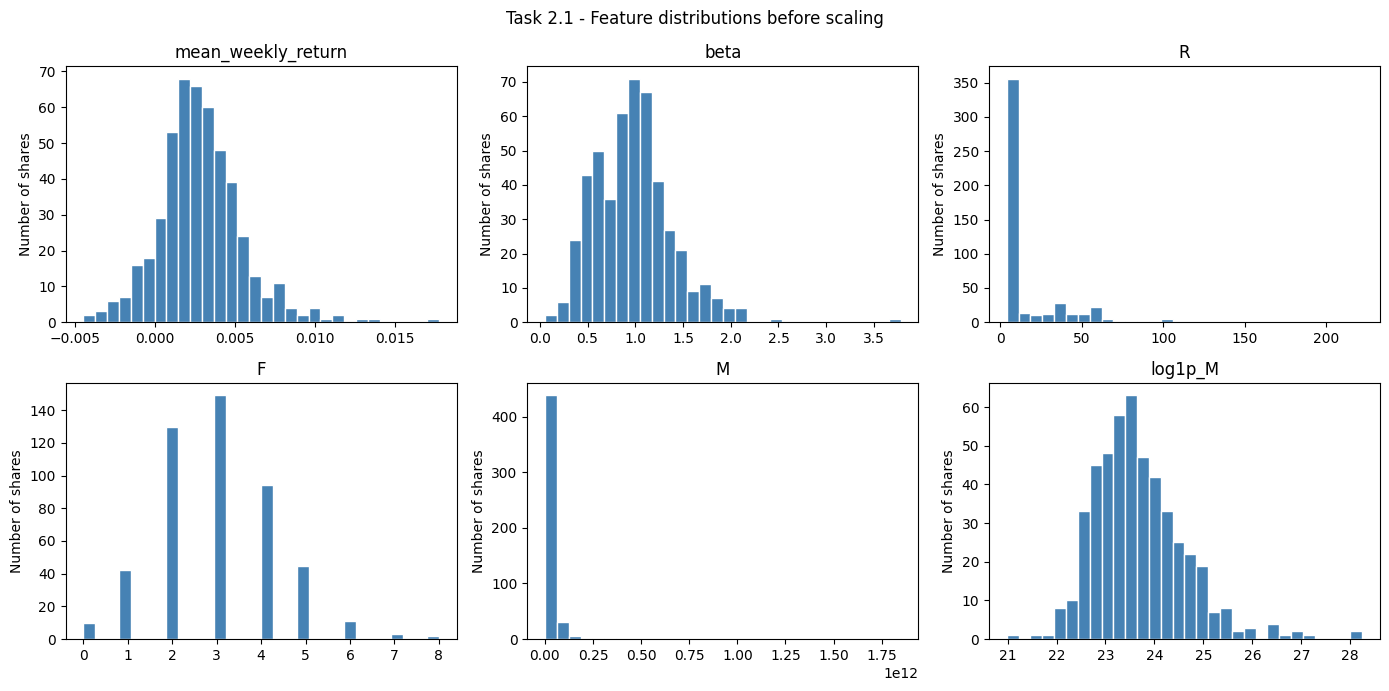

In [30]:
#Task 2.1 - Inspect skew and outliers before scaling
check_cols = ["mean_weekly_return", "beta", "R", "F", "M", "log1p_M"]
rows = []
for col in check_cols:
    s = df[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    outside_iqr = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())   # beyond 1.5 x IQR
    z = (s - s.mean()) / s.std()
    rows.append({"feature": col, "skew": skew(s), "outliers_1.5xIQR": outside_iqr,
                 "abs_z_above_3": int((z.abs() > 3).sum())})
skew_table = pd.DataFrame(rows).set_index("feature")

# Evidence for the other skewed variables: what the skew would be if log1p were applied to R and F
skew_table["skew_if_log1p"] = [skew(np.log1p(df[c])) if c in ["R", "F"] else np.nan for c in skew_table.index]
print(skew_table.round(2))

# Histograms of the five features (Monetary shown before and after log1p)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), check_cols):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Number of shares")
plt.suptitle("Task 2.1 - Feature distributions before scaling")
plt.tight_layout()
plt.savefig("data/processed/figures/feature_distributions.png", dpi=150)
plt.show()

In [31]:
#Task 2.1 - Standardise each matrix separately (mean 0, standard deviation 1)
#Decision: only Monetary is log-transformed. R, F, return and beta are only standardised.
#No shares are removed as outliers - they are genuine values, and removing them would break the common share set.
scaler_risk = StandardScaler()
scaler_rfm = StandardScaler()
X_risk = scaler_risk.fit_transform(X_risk_raw)
X_rfm = scaler_rfm.fit_transform(X_rfm_raw)

print("Risk and return matrix:", X_risk.shape, "| RFM matrix:", X_rfm.shape)
print("\nRisk and return after scaling:")
print(pd.DataFrame(X_risk, columns=risk_cols).agg(["mean", "std"]).round(3))
print("\nRFM after scaling:")
print(pd.DataFrame(X_rfm, columns=rfm_cols).agg(["mean", "std"]).round(3))


Risk and return matrix: (486, 2) | RFM matrix: (486, 3)

Risk and return after scaling:
      mean_weekly_return   beta
mean              -0.000 -0.000
std                1.001  1.001

RFM after scaling:
          R      F  log1p_M
mean -0.000 -0.000   -0.000
std   1.001  1.001    1.001


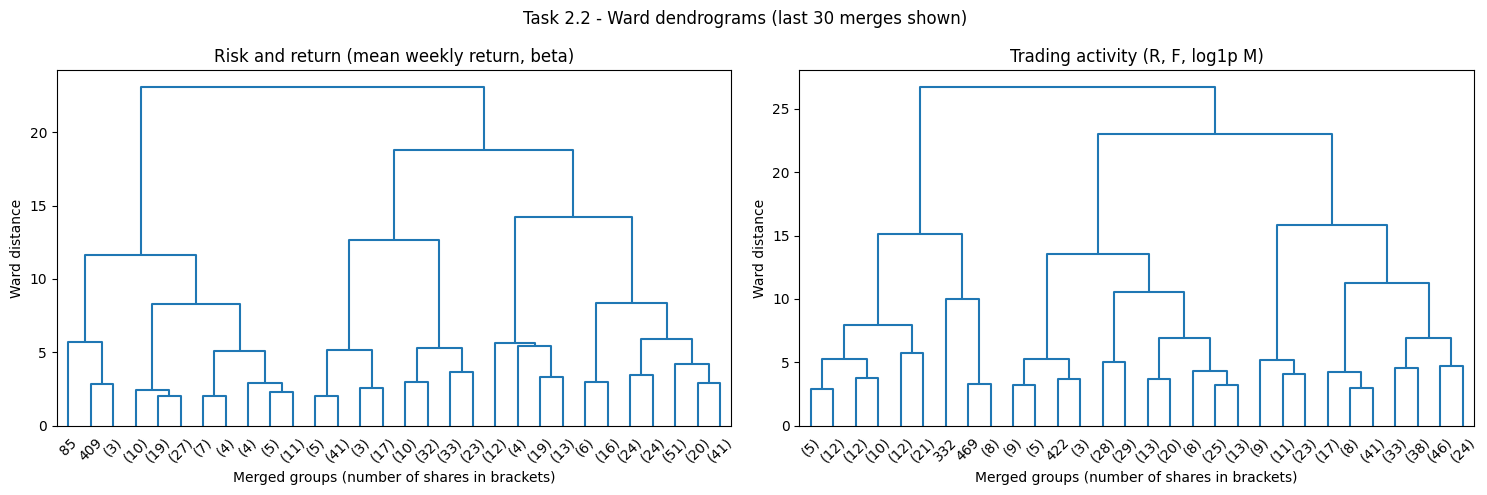

In [32]:
#Task 2.2 - Ward linkage with Euclidean distance: one dendrogram for each feature matrix
Z_risk = linkage(X_risk, method="ward", metric="euclidean")
Z_rfm = linkage(X_rfm, method="ward", metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, Z, title in zip(axes, [Z_risk, Z_rfm],
                        ["Risk and return (mean weekly return, beta)", "Trading activity (R, F, log1p M)"]):
    # color_threshold=0 means no colour cut-off is drawn: the final k is chosen from several diagnostics, not from colours
    dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, color_threshold=0, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Merged groups (number of shares in brackets)")
    ax.set_ylabel("Ward distance")
plt.suptitle("Task 2.2 - Ward dendrograms (last 30 merges shown)")
plt.tight_layout()
plt.savefig("data/processed/figures/dendrograms.png", dpi=150)
plt.show()

Ward - risk and return matrix
   silhouette  smallest  largest                             sizes
k                                                                 
2       0.339        92      394                         [394, 92]
3       0.274        92      230                    [230, 164, 92]
4       0.282        48      182                [182, 164, 92, 48]
5       0.304        48      182             [182, 98, 92, 66, 48]
6       0.320         5      182          [182, 98, 87, 66, 48, 5]
7       0.324         5      160      [160, 98, 87, 66, 48, 22, 5]
8       0.321         5      160  [160, 98, 66, 56, 48, 31, 22, 5]

Ward - RFM matrix
   silhouette  smallest  largest                              sizes
k                                                                  
2       0.368        82      404                          [404, 82]
3       0.304        82      250                     [250, 154, 82]
4       0.289        43      207                 [207, 154, 82, 43]
5       

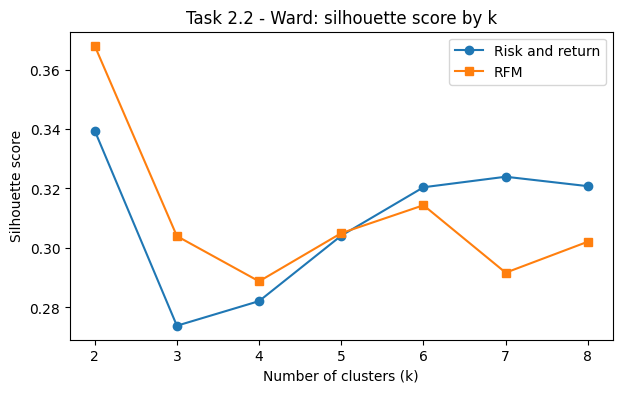

In [33]:
#Task 2.2 - Compare 2 to 8 clusters from the Ward tree using silhouette score and cluster sizes
def ward_diagnostics(X, Z):
    rows = []
    for k in range(2, 9):
        labels = fcluster(Z, t=k, criterion="maxclust")          # cut the same tree into k groups
        sizes = pd.Series(labels).value_counts().sort_values(ascending=False).tolist()
        rows.append({"k": k, "silhouette": silhouette_score(X, labels),
                     "smallest": min(sizes), "largest": max(sizes), "sizes": sizes})
    return pd.DataFrame(rows).set_index("k")

ward_diag_risk = ward_diagnostics(X_risk, Z_risk)
ward_diag_rfm = ward_diagnostics(X_rfm, Z_rfm)

print("Ward - risk and return matrix")
print(ward_diag_risk.round(3))
print("\nWard - RFM matrix")
print(ward_diag_rfm.round(3))

plt.figure(figsize=(7, 4))
plt.plot(ward_diag_risk.index, ward_diag_risk["silhouette"], marker="o", label="Risk and return")
plt.plot(ward_diag_rfm.index, ward_diag_rfm["silhouette"], marker="s", label="RFM")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Task 2.2 - Ward: silhouette score by k")
plt.legend()
plt.savefig("data/processed/figures/ward_silhouette.png", dpi=150)
plt.show()


In [34]:
#Task 2.2 - Interpretable profiles for the candidate cluster counts (original units)
def profile_risk(labels):
    t = df[risk_cols].copy()
    t["cluster"] = labels
    out = t.groupby("cluster").agg(n_shares=("beta", "size"), mean_weekly_return=("mean_weekly_return", "mean"),
                                   beta=("beta", "mean"))
    out["mean_weekly_return_%"] = out.pop("mean_weekly_return") * 100
    return out.round(3)

def profile_rfm(labels):
    t = df[["R", "F", "M"]].copy()
    t["cluster"] = labels
    out = t.groupby("cluster").agg(n_shares=("R", "size"), R_days=("R", "mean"), F_days=("F", "mean"),
                                   median_M=("M", "median"))
    out["median_M_USD_bn"] = out.pop("median_M") / 1e9
    return out.round(2)

# Chosen cluster counts for Ward (rule below is my own choice, stated in the report):
# k = 3 to 6, smallest cluster at least 5% of the shares (24 of 486), then the highest silhouette score
K_WARD_RISK = 5   # silhouette 0.304, smallest cluster 48 shares
K_WARD_RFM = 3    # silhouette 0.304, smallest cluster 82 shares

for name, Z, k_chosen, func in [("Risk and return", Z_risk, K_WARD_RISK, profile_risk),
                                ("RFM", Z_rfm, K_WARD_RFM, profile_rfm)]:
    for k in [k_chosen - 1, k_chosen, k_chosen + 1]:
        if 2 <= k <= 8:
            print(f"Ward {name}, k = {k}" + ("   <-- chosen" if k == k_chosen else ""))
            print(func(fcluster(Z, t=k, criterion="maxclust")))
            print()

Ward Risk and return, k = 4
         n_shares   beta  mean_weekly_return_%
cluster                                       
1              92  1.298                 0.632
2             164  0.601                 0.287
3              48  1.628                 0.200
4             182  0.973                 0.132

Ward Risk and return, k = 5   <-- chosen
         n_shares   beta  mean_weekly_return_%
cluster                                       
1              92  1.298                 0.632
2              66  0.439                 0.088
3              98  0.710                 0.422
4              48  1.628                 0.200
5             182  0.973                 0.132

Ward Risk and return, k = 6
         n_shares   beta  mean_weekly_return_%
cluster                                       
1               5  2.339                 1.291
2              87  1.238                 0.594
3              66  0.439                 0.088
4              98  0.710                 0.422
5       

K-Means - risk and return matrix
   inertia  silhouette  smallest  largest                             sizes
k                                                                          
2  621.634       0.387       143      343                        [343, 143]
3  461.179       0.329       119      202                   [202, 165, 119]
4  371.577       0.327        40      160               [160, 154, 132, 40]
5  309.613       0.341        27      166           [166, 131, 112, 50, 27]
6  265.097       0.335         5      156        [156, 127, 105, 50, 43, 5]
7  227.183       0.328         5      128     [128, 103, 85, 77, 47, 41, 5]
8  194.362       0.354         5      136  [136, 79, 78, 76, 43, 40, 29, 5]

K-Means - RFM matrix
    inertia  silhouette  smallest  largest                              sizes
k                                                                            
2  1066.832       0.423        68      418                          [418, 68]
3   796.614       0.325    

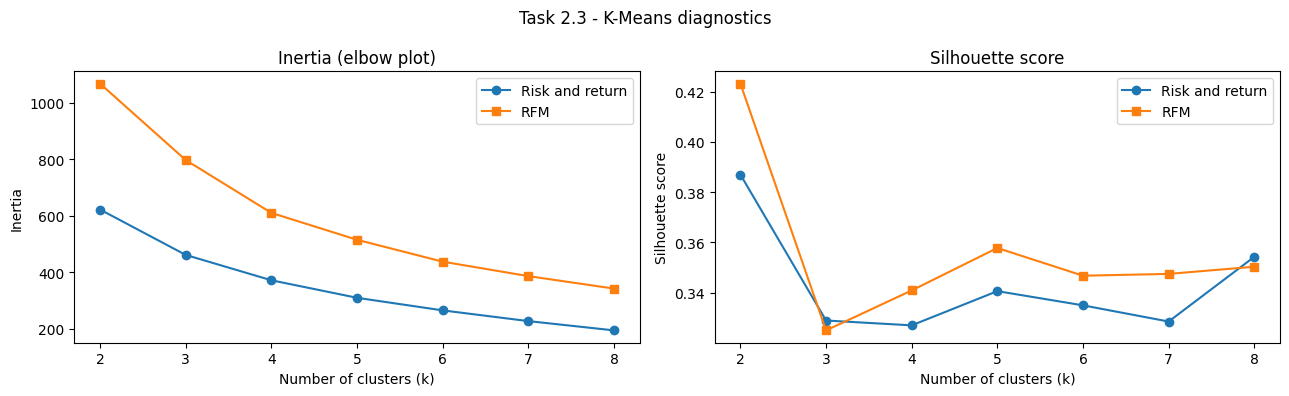

In [35]:
#Task 2.3 - K-Means: compare k = 2 to 8 using inertia, silhouette score and cluster sizes
def kmeans_diagnostics(X):
    rows = []
    for k in range(2, 9):
        #k-means++ start, 50 different initialisations (the best one is kept), fixed seed
        km = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=RANDOM_SEED)
        labels = km.fit_predict(X)
        sizes = pd.Series(labels).value_counts().sort_values(ascending=False).tolist()
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, labels),
                     "smallest": min(sizes), "largest": max(sizes), "sizes": sizes})
    return pd.DataFrame(rows).set_index("k")

km_diag_risk = kmeans_diagnostics(X_risk)
km_diag_rfm = kmeans_diagnostics(X_rfm)

print("K-Means - risk and return matrix")
print(km_diag_risk.round(3))
print("\nK-Means - RFM matrix")
print(km_diag_rfm.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for diag, name, marker in [(km_diag_risk, "Risk and return", "o"), (km_diag_rfm, "RFM", "s")]:
    axes[0].plot(diag.index, diag["inertia"], marker=marker, label=name)
    axes[1].plot(diag.index, diag["silhouette"], marker=marker, label=name)
axes[0].set_title("Inertia (elbow plot)")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[0].legend()
axes[1].legend()
plt.suptitle("Task 2.3 - K-Means diagnostics")
plt.tight_layout()
plt.savefig("data/processed/figures/kmeans_diagnostics.png", dpi=150)
plt.show()

In [36]:
#Task 2.3 - Choose k for K-Means (same rule as for Ward) and test how much the starting points matter
#Chosen cluster counts for K-Means (rule below is my own choice, stated in the report):
#k = 3 to 6, smallest cluster at least 5% of the shares (24 of 486), then the highest silhouette score
K_KM_RISK = 5     # silhouette 0.341, smallest cluster 27 shares
K_KM_RFM = 4      # silhouette 0.341, smallest cluster 61 shares

def initialisation_check(X, k, runs=20):
    #Run K-Means 20 times with ONE random start each, then compare with the best-of-50 solution
    best = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=RANDOM_SEED).fit(X)
    inertias, aris = [], []
    for seed in range(runs):
        single = KMeans(n_clusters=k, init="random", n_init=1, random_state=seed).fit(X)
        inertias.append(single.inertia_)
        aris.append(adjusted_rand_score(best.labels_, single.labels_))
    return {"best_of_50_inertia": round(best.inertia_, 2),
            "single_start_inertia_min": round(min(inertias), 2),
            "single_start_inertia_max": round(max(inertias), 2),
            "runs_matching_best_ARI_above_0.95": int(sum(a > 0.95 for a in aris)),
            "runs": runs}

print("Risk and return, k =", K_KM_RISK, ":", initialisation_check(X_risk, K_KM_RISK))
print("RFM, k =", K_KM_RFM, ":", initialisation_check(X_rfm, K_KM_RFM))


Risk and return, k = 5 : {'best_of_50_inertia': 309.61, 'single_start_inertia_min': 309.84, 'single_start_inertia_max': 333.07, 'runs_matching_best_ARI_above_0.95': 1, 'runs': 20}
RFM, k = 4 : {'best_of_50_inertia': 609.83, 'single_start_inertia_min': 609.83, 'single_start_inertia_max': 715.26, 'runs_matching_best_ARI_above_0.95': 10, 'runs': 20}


In [37]:
# Task 2.4 - The four baseline solutions (Ward and K-Means on each matrix), all on the same shares
df["ward_risk"] = fcluster(Z_risk, t=K_WARD_RISK, criterion="maxclust")
df["ward_rfm"] = fcluster(Z_rfm, t=K_WARD_RFM, criterion="maxclust")
df["km_risk"] = KMeans(n_clusters=K_KM_RISK, init="k-means++", n_init=50, random_state=RANDOM_SEED).fit_predict(X_risk) + 1
df["km_rfm"] = KMeans(n_clusters=K_KM_RFM, init="k-means++", n_init=50, random_state=RANDOM_SEED).fit_predict(X_rfm) + 1

# Save the feature table with all cluster assignments (required by the brief)
assign_cols = ["sector", "mean_weekly_return", "beta", "R", "F", "M", "log1p_M",
               "ward_risk", "km_risk", "ward_rfm", "km_rfm"]
df[assign_cols].to_csv("data/processed/cluster_assignments.csv")

# Cluster profiles in original units
for col, func, title in [("ward_risk", profile_risk, "Ward - risk and return"),
                         ("km_risk", profile_risk, "K-Means - risk and return"),
                         ("ward_rfm", profile_rfm, "Ward - RFM"),
                         ("km_rfm", profile_rfm, "K-Means - RFM")]:
    print(title)
    print(func(df[col]))
    print()

Ward - risk and return
         n_shares   beta  mean_weekly_return_%
cluster                                       
1              92  1.298                 0.632
2              66  0.439                 0.088
3              98  0.710                 0.422
4              48  1.628                 0.200
5             182  0.973                 0.132

K-Means - risk and return
         n_shares   beta  mean_weekly_return_%
cluster                                       
1             112  1.020                 0.034
2             166  0.996                 0.427
3             131  0.533                 0.206
4              27  1.559                 0.928
5              50  1.632                 0.241

Ward - RFM
         n_shares  R_days  F_days  median_M_USD_bn
cluster                                           
1              82   58.30    2.10            17.85
2             154   13.68    2.86            39.70
3             250   12.12    3.36            11.18

K-Means - RFM
         n

PCA: PC1 explains 45.8% and PC2 explains 33.6% of the variance in the RFM matrix


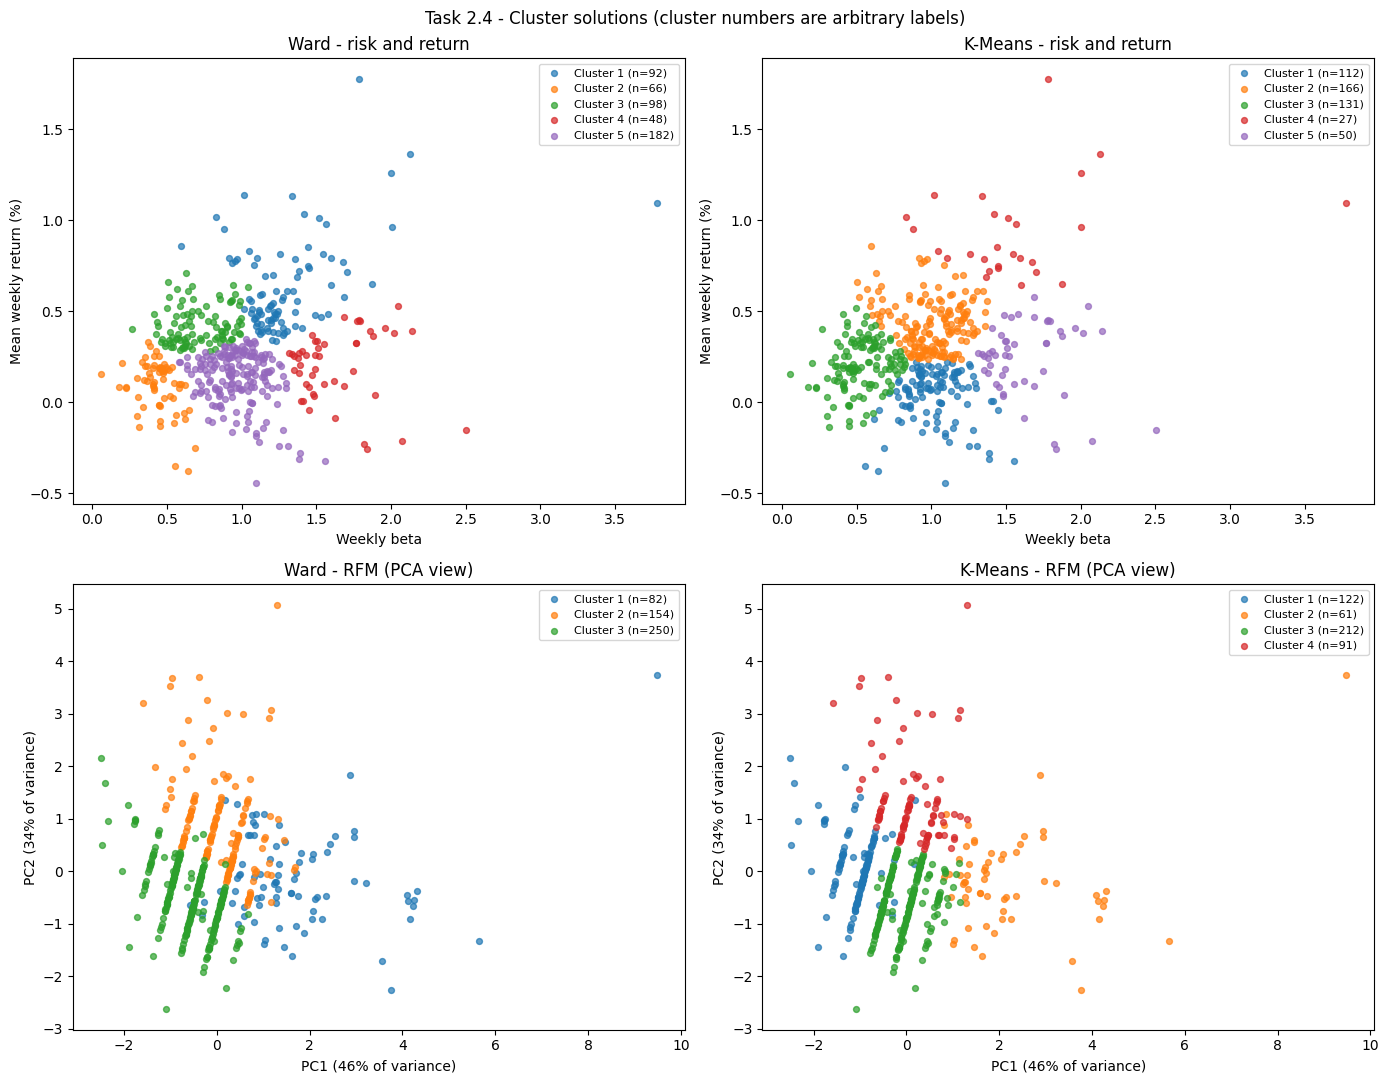

In [38]:
#Task 2.4 - Labelled two-dimensional plots of the four solutions
#Risk and return already has 2 features, so it is plotted directly in original units.
#RFM has 3 features, so PCA squeezes the 3 standardised features into 2 axes for display only
#(the clustering itself used all 3 features).
pca2 = PCA(n_components=2, random_state=RANDOM_SEED)
rfm_2d = pca2.fit_transform(X_rfm)
var1, var2 = pca2.explained_variance_ratio_ * 100
print(f"PCA: PC1 explains {var1:.1f}% and PC2 explains {var2:.1f}% of the variance in the RFM matrix")

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
panels = [("ward_risk", "Ward - risk and return", "risk", axes[0, 0]),
          ("km_risk", "K-Means - risk and return", "risk", axes[0, 1]),
          ("ward_rfm", "Ward - RFM (PCA view)", "rfm", axes[1, 0]),
          ("km_rfm", "K-Means - RFM (PCA view)", "rfm", axes[1, 1])]

for col, title, kind, ax in panels:
    for i, c in enumerate(sorted(df[col].unique())):
        mask = (df[col] == c).to_numpy()
        if kind == "risk":
            x, y = df.loc[mask, "beta"], df.loc[mask, "mean_weekly_return"] * 100
        else:
            x, y = rfm_2d[mask, 0], rfm_2d[mask, 1]
        ax.scatter(x, y, s=18, alpha=0.7, color=plt.cm.tab10(i), label=f"Cluster {c} (n={mask.sum()})")
    ax.set_title(title)
    ax.legend(fontsize=8)
    if kind == "risk":
        ax.set_xlabel("Weekly beta")
        ax.set_ylabel("Mean weekly return (%)")
    else:
        ax.set_xlabel(f"PC1 ({var1:.0f}% of variance)")
        ax.set_ylabel(f"PC2 ({var2:.0f}% of variance)")
plt.suptitle("Task 2.4 - Cluster solutions (cluster numbers are arbitrary labels)")
plt.tight_layout()
plt.savefig("data/processed/figures/cluster_plots.png", dpi=150)
plt.show()

In [39]:
#Task 2.4 - Compare Ward and K-Means on the same shares
summary_rows = []
for matrix_name, X, a, b in [("Risk and return", X_risk, "ward_risk", "km_risk"),
                             ("RFM", X_rfm, "ward_rfm", "km_rfm")]:
    ari = adjusted_rand_score(df[a], df[b])                      # 1 = identical groups, 0 = agreement by chance
    table = pd.crosstab(df[a], df[b], rownames=["Ward cluster"], colnames=["K-Means cluster"])
    rows_i, cols_i = linear_sum_assignment(-table.values)        # best one-to-one match of cluster numbers
    matched = table.values[rows_i, cols_i].sum() / len(df) * 100
    print(f"{matrix_name}: adjusted Rand index = {ari:.3f} | shares in matching clusters = {matched:.1f}%")
    print(table)
    print()
    summary_rows.append({"matrix": matrix_name, "ward_k": df[a].nunique(), "ward_silhouette": silhouette_score(X, df[a]),
                         "kmeans_k": df[b].nunique(), "kmeans_silhouette": silhouette_score(X, df[b]),
                         "ARI_between_methods": ari})
print(pd.DataFrame(summary_rows).round(3).to_string(index=False))

Risk and return: adjusted Rand index = 0.318 | shares in matching clusters = 60.5%
K-Means cluster    1   2   3   4   5
Ward cluster                        
1                  0  60   0  27   5
2                  5   0  61   0   0
3                  0  57  41   0   0
4                  3   0   0   0  45
5                104  49  29   0   0

RFM: adjusted Rand index = 0.318 | shares in matching clusters = 59.1%
K-Means cluster    1   2    3   4
Ward cluster                     
1                  4  57   14   7
2                 14   4   52  84
3                104   0  146   0

         matrix  ward_k  ward_silhouette  kmeans_k  kmeans_silhouette  ARI_between_methods
Risk and return       5            0.304         5              0.341                0.318
            RFM       3            0.304         4              0.341                0.318


             R      F  log1p_M
R        1.000 -0.346    0.152
F       -0.346  1.000    0.013
log1p_M  0.152  0.013    1.000


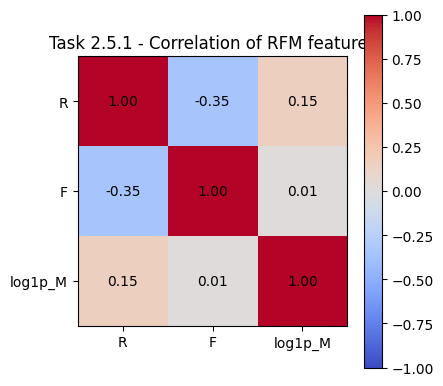

Share of variance on each principal component (%): [45.8 33.6 20.6]

Share of each feature's variance explained by the Ward RFM clusters:
R          0.642
F          0.119
log1p_M    0.516
dtype: float64


In [40]:
#Task 2.5.1 - Correlations among R, F and log1p(M)
corr = df[["R", "F", "log1p_M"]].corr(method="pearson")
print(corr.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(3))
ax.set_xticklabels(corr.columns)
ax.set_yticks(range(3))
ax.set_yticklabels(corr.columns)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im, ax=ax)
ax.set_title("Task 2.5.1 - Correlation of RFM features")
plt.tight_layout()
plt.savefig("data/processed/figures/rfm_correlation.png", dpi=150)
plt.show()

#How much of the RFM matrix's variance sits on one common direction (a sign that features move together)
pca_all = PCA().fit(X_rfm)
print("Share of variance on each principal component (%):", (pca_all.explained_variance_ratio_ * 100).round(1))

#Which scaled features separate the Ward RFM clusters most? (between-cluster share of each feature's variance)
scaled = pd.DataFrame(X_rfm, columns=rfm_cols, index=df.index)
total_ss = ((scaled - scaled.mean()) ** 2).sum()
between_ss = sum(len(g) * (g.mean() - scaled.mean()) ** 2 for _, g in scaled.groupby(df["ward_rfm"]))
print("\nShare of each feature's variance explained by the Ward RFM clusters:")
print((between_ss / total_ss).round(3))

Same shares: 486 | same k: 3
Adjusted Rand index, Ward RFM vs Ward R and F only: 0.291
Silhouette of the R and F only solution: 0.488

Ward R+F only   1   2    3
Ward RFM                  
1              79   0    3
2               9  59   86
3               1  66  183

Traded value by cluster - full RFM solution
          n_shares  median_M_USD_bn  min_M_USD_bn  max_M_USD_bn
ward_rfm                                                       
1               82            17.85          4.37       1825.34
2              154            39.70         18.75       1847.70
3              250            11.18          1.30         37.90

Traded value by cluster - R and F only solution
              n_shares  median_M_USD_bn  min_M_USD_bn  max_M_USD_bn
ward_rf_only                                                       
1                   89            20.85          4.37       1825.34
2                  125            17.70          3.69        623.30
3                  272            14.86     

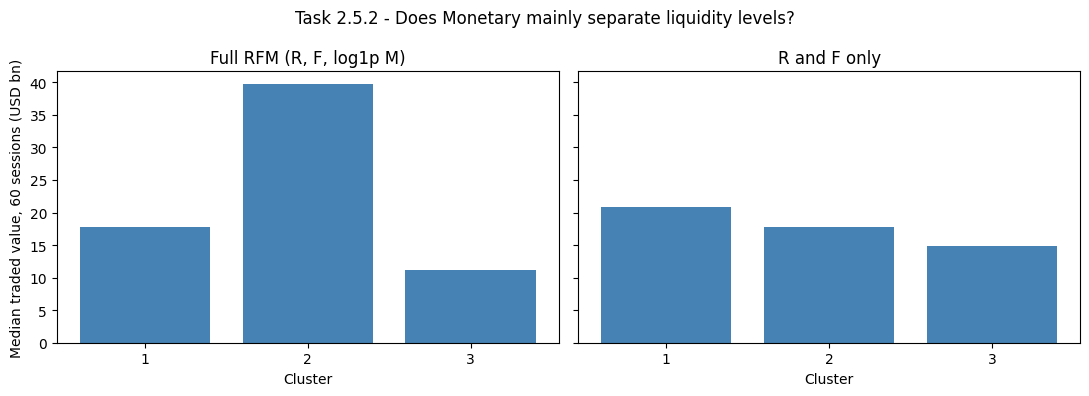

In [41]:
#Task 2.5.2 - Remove Monetary: repeat Ward on R and F only (same shares, same k, scaled again)
X_rf = StandardScaler().fit_transform(df[["R", "F"]])
Z_rf = linkage(X_rf, method="ward", metric="euclidean")
df["ward_rf_only"] = fcluster(Z_rf, t=K_WARD_RFM, criterion="maxclust")

ari_rf = adjusted_rand_score(df["ward_rfm"], df["ward_rf_only"])
print("Same shares:", len(df), "| same k:", K_WARD_RFM)
print(f"Adjusted Rand index, Ward RFM vs Ward R and F only: {ari_rf:.3f}")
print(f"Silhouette of the R and F only solution: {silhouette_score(X_rf, df['ward_rf_only']):.3f}")
print()
print(pd.crosstab(df["ward_rfm"], df["ward_rf_only"], rownames=["Ward RFM"], colnames=["Ward R+F only"]))

#Traded value (M) profile of each cluster, in USD billions, for both solutions
def traded_value_profile(label_col):
    g = df.groupby(label_col)["M"]
    return pd.DataFrame({"n_shares": g.size(), "median_M_USD_bn": g.median() / 1e9,
                         "min_M_USD_bn": g.min() / 1e9, "max_M_USD_bn": g.max() / 1e9}).round(2)

print("\nTraded value by cluster - full RFM solution")
profile_full = traded_value_profile("ward_rfm")
print(profile_full)
print("\nTraded value by cluster - R and F only solution")
profile_rf = traded_value_profile("ward_rf_only")
print(profile_rf)

print("\nRatio of highest to lowest cluster median M:")
print("  full RFM    :", round(profile_full["median_M_USD_bn"].max() / profile_full["median_M_USD_bn"].min(), 2))
print("  R and F only:", round(profile_rf["median_M_USD_bn"].max() / profile_rf["median_M_USD_bn"].min(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, prof, title in [(axes[0], profile_full, "Full RFM (R, F, log1p M)"), (axes[1], profile_rf, "R and F only")]:
    ax.bar(prof.index.astype(str), prof["median_M_USD_bn"], color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Cluster")
axes[0].set_ylabel("Median traded value, 60 sessions (USD bn)")
plt.suptitle("Task 2.5.2 - Does Monetary mainly separate liquidity levels?")
plt.tight_layout()
plt.savefig("data/processed/figures/monetary_removal.png", dpi=150)
plt.show()

#Save the final table with every cluster assignment
df[assign_cols + ["ward_rf_only"]].to_csv("data/processed/cluster_assignments.csv")

**Task 3 - Business Intelligence and Critical Review**

**Task 3.1 - Data mart design (written in the report, 200 words)**

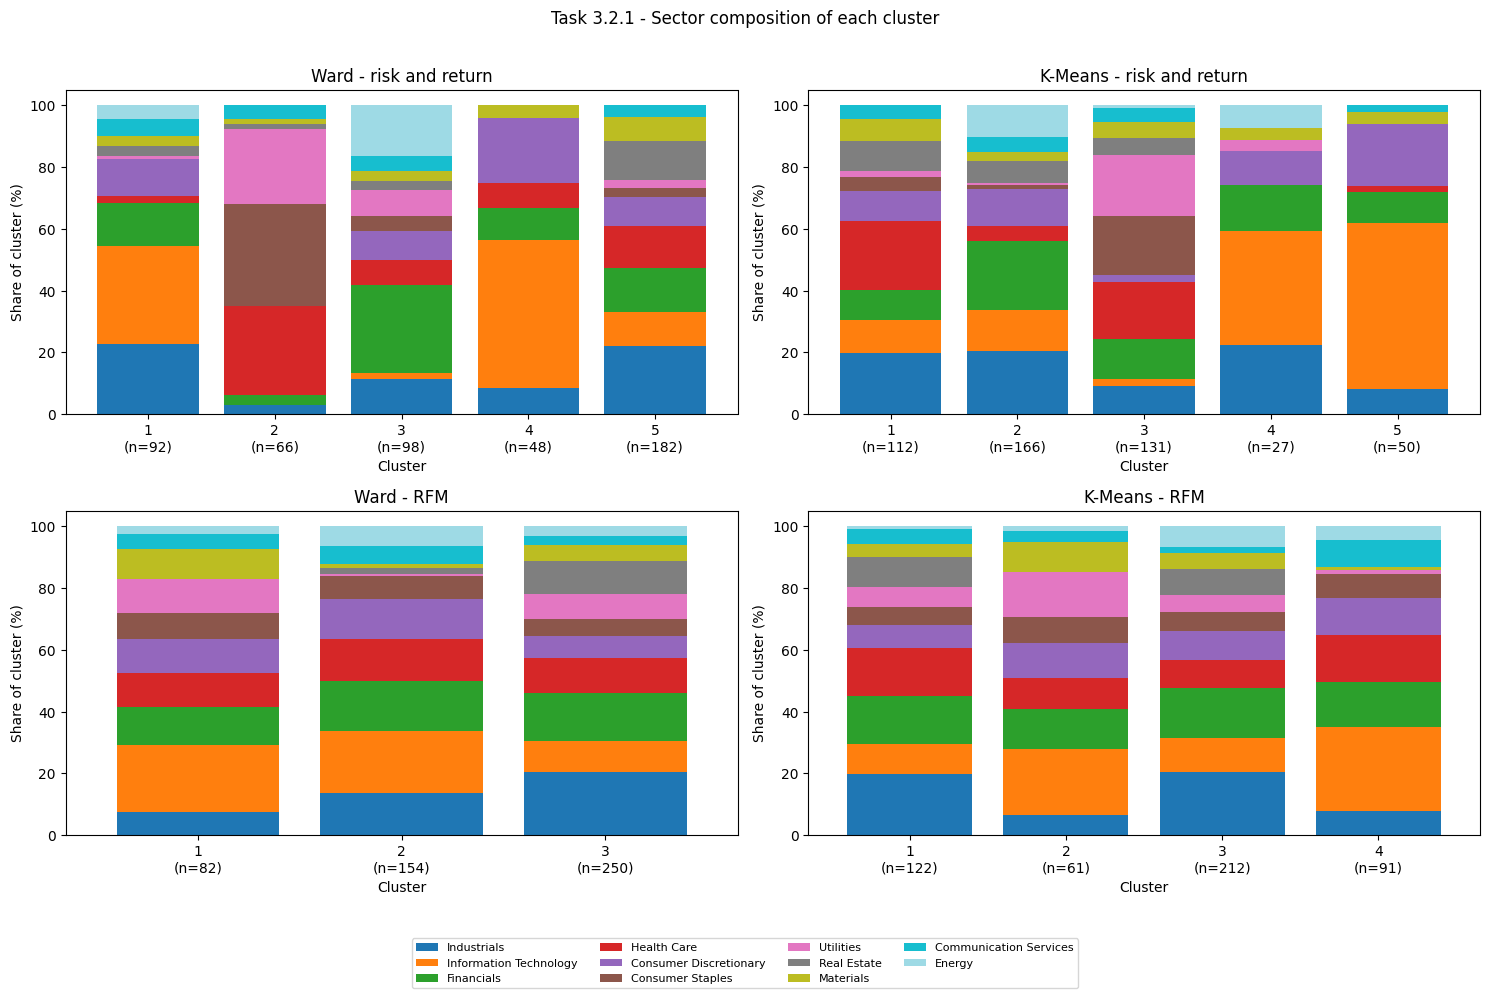

                 solution  cluster  n_shares         largest_sector  its_share_%  most_over_represented  times_overall_share
   Ward - risk and return        1        92 Information Technology         31.5 Information Technology                 2.07
   Ward - risk and return        2        66       Consumer Staples         33.3       Consumer Staples                 5.06
   Ward - risk and return        3        98             Financials         28.6                 Energy                 3.97
   Ward - risk and return        4        48 Information Technology         47.9 Information Technology                 3.15
   Ward - risk and return        5       182            Industrials         22.0            Real Estate                 2.05
K-Means - risk and return        1       112            Health Care         22.3            Health Care                 1.87
K-Means - risk and return        2       166             Financials         22.3                 Energy                 2.49


In [42]:
#Task 3.2.1 - Sector composition of every cluster (share of the cluster's shares in each GICS sector)
solutions = [("ward_risk", "Ward - risk and return"), ("km_risk", "K-Means - risk and return"),
             ("ward_rfm", "Ward - RFM"), ("km_rfm", "K-Means - RFM")]

overall_sector = df["sector"].value_counts(normalize=True) * 100     # sector mix of all 486 shares
sector_order = overall_sector.index.tolist()                         # biggest sector first

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (col, title) in zip(axes.ravel(), solutions):
    comp = pd.crosstab(df[col], df["sector"], normalize="index").reindex(columns=sector_order) * 100
    comp.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", legend=False, width=0.8)
    sizes = df[col].value_counts().sort_index()
    ax.set_xticklabels([f"{c}\n(n={n})" for c, n in sizes.items()], rotation=0)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Share of cluster (%)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8)
plt.suptitle("Task 3.2.1 - Sector composition of each cluster")
plt.tight_layout(rect=[0, 0.08, 1, 0.97])
plt.savefig("data/processed/figures/sector_composition.png", dpi=150)
plt.show()

#For each cluster: its largest sector, and the sector it over-represents most compared with the whole sample
rows = []
for col, title in solutions:
    for c in sorted(df[col].unique()):
        sub = df[df[col] == c]
        counts = sub["sector"].value_counts()
        share = counts / len(sub) * 100
        lift = (share / overall_sector.reindex(share.index))[counts >= 3]    # ignore sectors with fewer than 3 shares
        rows.append({"solution": title, "cluster": c, "n_shares": len(sub),
                     "largest_sector": share.idxmax(), "its_share_%": round(share.max(), 1),
                     "most_over_represented": lift.idxmax() if len(lift) else "-",
                     "times_overall_share": round(lift.max(), 2) if len(lift) else np.nan})
sector_table = pd.DataFrame(rows)
print(sector_table.to_string(index=False))
sector_table.to_csv("data/processed/sector_composition_table.csv", index=False)

In [43]:
#Task 3.2.1 - Compare the risk/return clusters with the RFM clusters (original units)
for risk_col, rfm_col, name in [("ward_risk", "ward_rfm", "Ward"), ("km_risk", "km_rfm", "K-Means")]:
    ari_cross = adjusted_rand_score(df[risk_col], df[rfm_col])
    print(f"=== {name}: risk/return clusters vs RFM clusters (adjusted Rand index = {ari_cross:.3f})")
    print(pd.crosstab(df[risk_col], df[rfm_col], rownames=["Risk/return cluster"], colnames=["RFM cluster"]))

    #What each risk/return cluster looks like in trading-activity terms
    activity = df.groupby(risk_col).agg(n_shares=("R", "size"), R_days=("R", "mean"), F_days=("F", "mean"),
                                        median_M=("M", "median"))
    activity["median_M_USD_bn"] = activity.pop("median_M") / 1e9
    print("\nActivity profile of each risk/return cluster")
    print(activity.round(2))

    #What each RFM cluster looks like in risk and return terms
    risk_view = df.groupby(rfm_col).agg(n_shares=("beta", "size"), beta=("beta", "mean"),
                                        mean_return=("mean_weekly_return", "mean"))
    risk_view["mean_weekly_return_%"] = risk_view.pop("mean_return") * 100
    print("\nRisk and return profile of each RFM cluster")
    print(risk_view.round(3))
    print()

=== Ward: risk/return clusters vs RFM clusters (adjusted Rand index = 0.039)
RFM cluster           1   2    3
Risk/return cluster             
1                    19  37   36
2                    16  23   27
3                    10  35   53
4                     9  20   19
5                    28  39  115

Activity profile of each risk/return cluster
           n_shares  R_days  F_days  median_M_USD_bn
ward_risk                                           
1                92   23.67    3.20            24.18
2                66   26.20    2.89            17.70
3                98   16.91    2.70            17.65
4                48   23.54    3.23            28.70
5               182   17.71    3.01            12.98

Risk and return profile of each RFM cluster
          n_shares   beta  mean_weekly_return_%
ward_rfm                                       
1               82  1.009                 0.286
2              154  1.010                 0.338
3              250  0.940             

In [44]:
#Task 3.2.2 - Collect the sensitivity results in one table
sensitivity = pd.DataFrame({
    "measure": [
        "Correlation R and F",
        "Correlation R and log1p(M)",
        "Correlation F and log1p(M)",
        "Variance on first principal component (%)",
        "Share of R variance explained by Ward RFM clusters",
        "Share of F variance explained by Ward RFM clusters",
        "Share of log1p(M) variance explained by Ward RFM clusters",
        "Adjusted Rand index, Ward RFM vs Ward R and F only",
        "Median traded value, highest / lowest cluster, full RFM",
        "Median traded value, highest / lowest cluster, R and F only",
    ],
    "value": [
        corr.loc["R", "F"], corr.loc["R", "log1p_M"], corr.loc["F", "log1p_M"],
        pca_all.explained_variance_ratio_[0] * 100,
        (between_ss / total_ss)["R"], (between_ss / total_ss)["F"], (between_ss / total_ss)["log1p_M"],
        ari_rf,
        profile_full["median_M_USD_bn"].max() / profile_full["median_M_USD_bn"].min(),
        profile_rf["median_M_USD_bn"].max() / profile_rf["median_M_USD_bn"].min(),
    ],
})
print(sensitivity.round(3).to_string(index=False))
sensitivity.to_csv("data/processed/sensitivity_summary.csv", index=False)

                                                    measure  value
                                        Correlation R and F -0.346
                                 Correlation R and log1p(M)  0.152
                                 Correlation F and log1p(M)  0.013
                  Variance on first principal component (%) 45.794
         Share of R variance explained by Ward RFM clusters  0.642
         Share of F variance explained by Ward RFM clusters  0.119
  Share of log1p(M) variance explained by Ward RFM clusters  0.516
         Adjusted Rand index, Ward RFM vs Ward R and F only  0.291
    Median traded value, highest / lowest cluster, full RFM  3.551
Median traded value, highest / lowest cluster, R and F only  1.403


Average pairwise correlation of weekly returns, all shares: 0.3

Ward risk/return clusters
 group  n_shares  avg_corr_within  avg_corr_with_other_shares
     1        92            0.374                       0.296
     2        66            0.312                       0.205
     3        98            0.325                       0.275
     4        48            0.438                       0.296
     5       182            0.367                       0.305

K-Means risk/return clusters
 group  n_shares  avg_corr_within  avg_corr_with_other_shares
     1       112            0.362                       0.309
     2       166            0.365                       0.302
     3       131            0.302                       0.232
     4        27            0.358                       0.280
     5        50            0.444                       0.291

GICS sectors (for comparison)
                 group  n_shares  avg_corr_within  avg_corr_with_other_shares
Communication Services    

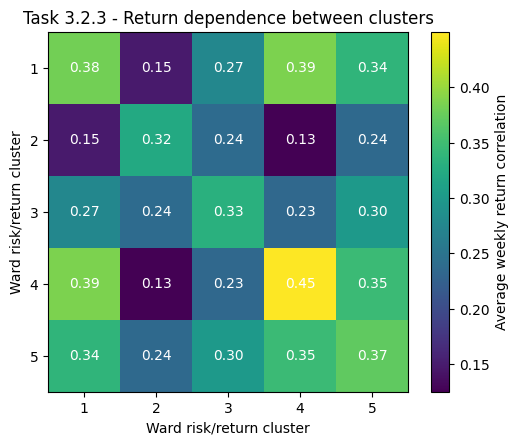

In [45]:
#Task 3.2.3 - Return dependencies: do shares with similar risk/return profiles also move together?
rets = weekly_returns[df.index]            # weekly returns of the 486 shares (207 weeks)
corr_all = rets.corr()
off_diag = ~np.eye(len(corr_all), dtype=bool)
print("Average pairwise correlation of weekly returns, all shares:", round(corr_all.values[off_diag].mean(), 3))

def within_between(labels):
    #Average correlation inside each group, and between that group and all other shares
    rows = []
    for g in sorted(labels.unique()):
        members = labels.index[labels == g]
        others = labels.index[labels != g]
        block = corr_all.loc[members, members].values
        within = block[~np.eye(len(members), dtype=bool)].mean()
        between = corr_all.loc[members, others].values.mean()
        rows.append({"group": g, "n_shares": len(members), "avg_corr_within": round(within, 3),
                     "avg_corr_with_other_shares": round(between, 3)})
    return pd.DataFrame(rows)

print("\nWard risk/return clusters")
print(within_between(df["ward_risk"]).to_string(index=False))
print("\nK-Means risk/return clusters")
print(within_between(df["km_risk"]).to_string(index=False))
print("\nGICS sectors (for comparison)")
print(within_between(df["sector"]).to_string(index=False))

#Heatmap: average correlation between every pair of Ward risk/return clusters (the diagonal is within-cluster)
groups = sorted(df["ward_risk"].unique())
matrix = np.array([[corr_all.loc[df.index[df["ward_risk"] == a], df.index[df["ward_risk"] == b]].values.mean()
                    for b in groups] for a in groups])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(matrix, cmap="viridis")
ax.set_xticks(range(len(groups)))
ax.set_xticklabels(groups)
ax.set_yticks(range(len(groups)))
ax.set_yticklabels(groups)
for i in range(len(groups)):
    for j in range(len(groups)):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color="white")
plt.colorbar(im, ax=ax, label="Average weekly return correlation")
ax.set_xlabel("Ward risk/return cluster")
ax.set_ylabel("Ward risk/return cluster")
ax.set_title("Task 3.2.3 - Return dependence between clusters")
plt.tight_layout()
plt.savefig("data/processed/figures/return_dependence.png", dpi=150)
plt.show()

In [46]:
#zip and download all saved files
!zip -r data.zip data
from google.colab import files
files.download("data.zip")

  adding: data/ (stored 0%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/risk_return_features.csv (deflated 60%)
  adding: data/processed/sensitivity_summary.csv (deflated 49%)
  adding: data/processed/acquisition_log.csv (deflated 90%)
  adding: data/processed/included_tickers.csv (deflated 44%)
  adding: data/processed/figures/ (stored 0%)
  adding: data/processed/figures/return_dependence.png (deflated 8%)
  adding: data/processed/figures/rfm_correlation.png (deflated 12%)
  adding: data/processed/figures/sector_composition.png (deflated 24%)
  adding: data/processed/figures/feature_distributions.png (deflated 23%)
  adding: data/processed/figures/cluster_plots.png (deflated 11%)
  adding: data/processed/figures/monetary_removal.png (deflated 18%)
  adding: data/processed/figures/ward_silhouette.png (deflated 8%)
  adding: data/processed/figures/kmeans_diagnostics.png (deflated 9%)
  adding: data/processed/figures/dendrograms.png (deflated 17%)
  adding: data/proce

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>